<a href="https://colab.research.google.com/github/APosokhova893/python_basics/blob/main/%2216_1_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BE%D1%80%D0%B5%D0%BD%D0%B4%D0%BD%D0%BE%D1%97_%D0%BF%D0%BB%D0%B0%D1%82%D0%B8_%D0%B7%D0%B0_%D0%B6%D0%B8%D1%82%D0%BB%D0%BE_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування орендної плати за житло

## Мета завдання
Застосувати знання з лекції для побудови моделі лінійної регресії, що прогнозує орендну плату за житло в Індії. Ви пройдете весь цикл вирішення задачі машинного навчання: від дослідницького аналізу до оцінки якості моделі.

## Опис датасету
**House Rent Prediction Dataset** містить інформацію про 4700+ оголошень про оренду житла в Індії з такими параметрами:
- **BHK**: Кількість спалень, залів, кухонь
- **Rent**: Орендна плата (цільова змінна)
- **Size**: Площа в квадратних футах
- **Floor**: Поверх та загальна кількість поверхів
- **Area Type**: Тип розрахунку площі
- **Area Locality**: Район
- **City**: Місто
- **Furnishing Status**: Стан меблювання
- **Tenant Preferred**: Тип орендаря
- **Bathroom**: Кількість ванних кімнат
- **Point of Contact**: Контактна особа

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `House_Rent_Dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (включно з типами даних та кількістю значень)


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('16/House_Rent_Dataset.csv')


In [4]:
df.shape

(4746, 12)

In [5]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


## Завдання 2: Дослідницький аналіз даних (EDA) (5 балів)

**Що потрібно зробити:**
1. **Аналіз пропущених значень.** Перевірте наявність і відсоток пропущених значень у кожній колонці
2. **Базова статистика.** Обчисліть базову статистику (середнє, квартилі, стандартне відхилення) для числових змінних.
3. **Аналіз цільової змінної.** Побудуйте гістограму розподілу цільової змінної (Rent)
4. **Робота з викидами.** Знайдіть та видаліть викиди в цільовій змінній (якщо є). Визначити викиди можна будь-яким зрозумілим для вас способом, як варіант - таким, що використовується в побудові box-plot (https://en.wikipedia.org/wiki/Box_plot#Example_with_outliers).
5. **Аналіз категоріальних змінних.** Виведіть кількість унікальних значень для кожної з категоріальних колонок.


In [7]:
missing_data = df.isnull().sum()
missing_percent= (missing_data / len(df))* 100
missing_percent

,0
Posted On,0.0
BHK,0.0
Rent,0.0
Size,0.0
Floor,0.0
Area Type,0.0
Area Locality,0.0
City,0.0
Furnishing Status,0.0
Tenant Preferred,0.0


In [8]:
stats = df[['BHK','Rent','Size','Bathroom']].describe()
stats.round(2)

,BHK,Rent,Size,Bathroom
count,4746.00,4746.00,4746.00,4746.00
mean,2.08,34993.45,967.49,1.97
std,0.83,78106.41,634.20,0.88
min,1.00,1200.00,10.00,1.00
25%,2.00,10000.00,550.00,1.00
50%,2.00,16000.00,850.00,2.00
75%,3.00,33000.00,1200.00,2.00
max,6.00,3500000.00,8000.00,10.00


In [9]:
#Розподіл вартості оренди
fig= px.histogram(
    df,
    x='Rent',
    nbins=100,
    title='Розподіл цільової змінної(вартість оренди)',
    labels={'Rent':'Вартісь оренди','count': 'Кількість квартир'}
)
fig.update_layout(
    showlegend=False,
    height=400
)
fig.show()

In [10]:
fig=px.box(df,y='Rent', title='Викиди у вартості оренди')
fig.show()

In [11]:
Q1 = df['Rent'].quantile(0.25)
Q3 = df['Rent'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(lower_bound, upper_bound)

-24500.0 67500.0


In [12]:
outliers = df[
    (df['Rent'] < lower_bound) |
    (df['Rent'] > upper_bound)
]

len(outliers)

520

In [13]:
df_clean = df[
    (df['Rent'] >= lower_bound) &
    (df['Rent'] <= upper_bound)
].copy()

df_clean.shape

(4226, 12)

In [14]:
df_clean['Rent'].max()

67000

In [15]:
categorical=df_clean.select_dtypes(include='object')
categorical.nunique()

,0
Posted On,80
Floor,340
Area Type,3
Area Locality,1997
City,6
Furnishing Status,3
Tenant Preferred,3
Point of Contact,3



## Завдання 3: Аналіз кореляцій та взаємозв'язків (3 бали)

**Що потрібно зробити:**
1. Обчисліть матрицю кореляцій для числових змінних
2. Візуалізуйте кореляційну матрицю за допомогою heatmap
3. Побудуйте scatter plot між Size та Rent
4. Проаналізуйте взаємозв'язок між BHK та Rent за допомогою boxplot (який розподіл плати для різних значень BHK)


In [16]:
metrics_df = df_clean[['BHK','Rent','Size','Bathroom']].dropna()
correlation_matrix = metrics_df.corr()
correlation_matrix

,BHK,Rent,Size,Bathroom
BHK,1.000000,0.401268,0.698453,0.747918
Rent,0.401268,1.000000,0.393605,0.506528
Size,0.698453,0.393605,1.000000,0.680607
Bathroom,0.747918,0.506528,0.680607,1.000000


In [17]:
fig = px.imshow(
    correlation_matrix,
    text_auto='.2f',
    color_continuous_scale='RdBu_r',
    title='Кореляція між метриками взаємодії',
    labels=dict(color="Кореляція")
)
fig.update_layout(height=500)
fig.show()

In [18]:
fig = px.scatter(
    df_clean,
    x='Size',
    y='Rent',
    title='Залежність оренди від площі'
)

fig.show()

In [19]:
fig = px.box(
    df_clean,
    x='BHK',
    y='Rent',
    title='Розподіл оренди за кількістю кімнат'
)

fig.show()

## Завдання 4: Feature Engineering та підготовка даних (4 бали)

**Що потрібно зробити:**
1. Закодуйте категоріальні змінні за допомогою One-Hot Encoding. Пригадайте, що в лекції ми говорили щодо кодування кат. змінних з великої кількістю різних значень і як працювати з такими випадками. Ви можете закодувати не всі кат. змінні, а лише ті, що вважаєте за потрібні (скажімо ті, що мають відносно небагато різних значень).
2. **Опціонально (по 0.5 бала за кожну доцільну ознаку):** Додайте нові ознаки, обчислені на основі наявних даних, які б на ваш погляд були корисними для моделі
3. Виберіть ознаки для побудови моделі (виключіть непотрібні колонки). Виключити можна, наприклад, ті колонки, які мають категоріальний тип і забагато (більше 20) різних значень. Треба виключити хоча б 1 колонку.
4. Розділіть дані на ознаки (X) та цільову змінну (y)
5. Застосуйте стандартизацію до числових ознак


In [20]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['Furnishing Status', 'City', 'Area Type']
)

In [21]:
df_encoded.head()

,Posted On,BHK,Rent,Size,Floor,Area Locality,Tenant Preferred,Bathroom,Point of Contact,Furnishing Status_Furnished,...,Furnishing Status_Unfurnished,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai,Area Type_Built Area,Area Type_Carpet Area,Area Type_Super Area
0,2022-05-18,2,10000,1100,Ground out of 2,Bandel,Bachelors/Family,2,Contact Owner,False,...,True,False,False,False,False,True,False,False,False,True
1,2022-05-13,2,20000,800,1 out of 3,"Phool Bagan, Kankurgachi",Bachelors/Family,1,Contact Owner,False,...,False,False,False,False,False,True,False,False,False,True
2,2022-05-16,2,17000,1000,1 out of 3,Salt Lake City Sector 2,Bachelors/Family,1,Contact Owner,False,...,False,False,False,False,False,True,False,False,False,True
3,2022-07-04,2,10000,800,1 out of 2,Dumdum Park,Bachelors/Family,1,Contact Owner,False,...,True,False,False,False,False,True,False,False,False,True
4,2022-05-09,2,7500,850,1 out of 2,South Dum Dum,Bachelors,1,Contact Owner,False,...,True,False,False,False,False,True,False,False,True,False


In [22]:
df_encoded['Floor'].unique()[:20]

array(['Ground out of 2', '1 out of 3', '1 out of 2', 'Ground out of 1',
       'Ground out of 4', '1 out of 4', '1 out of 1', 'Ground out of 3',
       '2 out of 3', '4 out of 5', '2 out of 2', '2 out of 5',
       '4 out of 14', '3 out of 3', '5 out of 5', '4 out of 4',
       '7 out of 8', '2 out of 4', '3 out of 4', '1 out of 5'],
      dtype=object)

In [23]:
df_encoded['Total_Floors'] = pd.to_numeric(
    df_encoded['Floor'].str.extract(r'out of (\d+)')[0],
    errors='coerce'
)

In [24]:
df_encoded[['Floor', 'Total_Floors']].head(10)

,Floor,Total_Floors
0,Ground out of 2,2.0
1,1 out of 3,3.0
2,1 out of 3,3.0
3,1 out of 2,2.0
4,1 out of 2,2.0
5,Ground out of 1,1.0
6,Ground out of 4,4.0
7,1 out of 2,2.0
8,1 out of 2,2.0
9,1 out of 3,3.0


In [25]:
df_encoded['Floor_Number'] = pd.to_numeric(
    df_encoded['Floor'].str.extract(r'^(\d+)')[0],
    errors='coerce'
)

In [26]:
df_encoded[['Floor', 'Floor_Number', 'Total_Floors']].head(10)

,Floor,Floor_Number,Total_Floors
0,Ground out of 2,NaN,2.0
1,1 out of 3,1.0,3.0
2,1 out of 3,1.0,3.0
3,1 out of 2,1.0,2.0
4,1 out of 2,1.0,2.0
5,Ground out of 1,NaN,1.0
6,Ground out of 4,NaN,4.0
7,1 out of 2,1.0,2.0
8,1 out of 2,1.0,2.0
9,1 out of 3,1.0,3.0


In [27]:
df_encoded.loc[
    df_encoded['Floor'].str.startswith('Ground'),
    'Floor_Number'
] = 0

In [28]:
df_encoded[['Floor_Number', 'Total_Floors']].isnull().sum()

,0
Floor_Number,28
Total_Floors,4


In [29]:
df_encoded.loc[
    df_encoded['Floor_Number'].isnull(),
    'Floor'
].unique()

array(['Upper Basement out of 4', 'Lower Basement out of 2',
       'Upper Basement out of 9', 'Upper Basement out of 16',
       'Upper Basement out of 10', 'Lower Basement out of 18',
       'Upper Basement out of 7', 'Upper Basement out of 22',
       'Lower Basement out of 3', 'Lower Basement out of 1',
       'Upper Basement out of 2', 'Upper Basement out of 3',
       'Upper Basement out of 5'], dtype=object)

In [30]:
df_encoded.loc[
    df_encoded['Floor'].str.startswith('Upper Basement'),
    'Floor_Number'
] = -1

In [31]:
df_encoded.loc[
    df_encoded['Floor'].str.startswith('Lower Basement'),
    'Floor_Number'
] = -2

In [32]:
df_encoded[['Floor_Number', 'Total_Floors']].isnull().sum()

,0
Floor_Number,0
Total_Floors,4


In [33]:
df_encoded.loc[
    df_encoded['Total_Floors'].isnull(),
    ['Floor', 'Floor_Number', 'Total_Floors']
]

,Floor,Floor_Number,Total_Floors
2553,3,3.0,NaN
2883,Ground,0.0,NaN
4490,1,1.0,NaN
4560,1,1.0,NaN


In [34]:
df_encoded = df_encoded.dropna(subset=['Total_Floors'])

In [35]:
df_encoded.shape

(4222, 23)

In [36]:
df_encoded.columns.tolist()

['Posted On',
 'BHK',
 'Rent',
 'Size',
 'Floor',
 'Area Locality',
 'Tenant Preferred',
 'Bathroom',
 'Point of Contact',
 'Furnishing Status_Furnished',
 'Furnishing Status_Semi-Furnished',
 'Furnishing Status_Unfurnished',
 'City_Bangalore',
 'City_Chennai',
 'City_Delhi',
 'City_Hyderabad',
 'City_Kolkata',
 'City_Mumbai',
 'Area Type_Built Area',
 'Area Type_Carpet Area',
 'Area Type_Super Area',
 'Total_Floors',
 'Floor_Number']

In [37]:
features = ['BHK', 'Size', 'Bathroom',
            'Floor_Number', 'Total_Floors']

In [38]:
encoded_columns = df_encoded.select_dtypes(include='bool').columns.tolist()
encoded_columns

['Furnishing Status_Furnished',
 'Furnishing Status_Semi-Furnished',
 'Furnishing Status_Unfurnished',
 'City_Bangalore',
 'City_Chennai',
 'City_Delhi',
 'City_Hyderabad',
 'City_Kolkata',
 'City_Mumbai',
 'Area Type_Built Area',
 'Area Type_Carpet Area',
 'Area Type_Super Area']

In [39]:
features = features + encoded_columns

In [40]:
len(features)

17

In [41]:
X = df_encoded[features]

In [42]:
y = df_encoded['Rent']

In [43]:
print(X.shape)
print(y.shape)

(4222, 17)
(4222,)


In [44]:
from sklearn.preprocessing import StandardScaler

In [45]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

In [46]:
from sklearn.model_selection import train_test_split

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [48]:
print(X_train.shape)
print(X_test.shape)

(3377, 17)
(845, 17)


In [49]:
numeric_features = ['BHK', 'Size', 'Bathroom',
                    'Floor_Number', 'Total_Floors']

In [50]:
scaler = StandardScaler()

In [51]:
X_train_scaled = X_train.copy()

X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train[numeric_features]
)

In [52]:
X_test_scaled = X_test.copy()

X_test_scaled[numeric_features] = scaler.transform(
    X_test[numeric_features]
)

In [53]:
X_train_scaled[numeric_features].head()

,BHK,Size,Bathroom,Floor_Number,Total_Floors
2557,0.055235,-0.865580,-1.137841,-0.431912,-0.223547
3754,0.055235,-0.605977,0.271213,0.130156,-0.062652
1461,0.055235,-0.203073,0.271213,2.097393,2.350769
3940,1.397174,2.343116,1.680266,-0.993979,-0.384442
3833,1.397174,1.061715,1.680266,-0.150878,-0.223547


## Завдання 5: Розділення даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на навчальну (80%) та тестову (20%) вибірки.
2. Створіть модель лінійної регресії.
3. Навчіть модель на навчальних даних.
4. Виведіть усі коефіцієнти моделі (ваги) та напишіть, які 2 ознаки найбільше впливають на прогноз.
5. Зробіть прогнози на тренувальній та тестовій вибірках.

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
model = LinearRegression()

In [56]:
model.fit(X_train_scaled, y_train)

LinearRegression()

In [57]:
model.coef_

array([ 2230.34518491,  4209.65400495,  2084.57454565,  -166.89620732,
        2622.51931966,  2862.91122849,  -874.97037703, -1987.94085146,
       -2490.313217  , -3798.86073449,  1646.21773737, -5685.76577389,
       -5177.96976643, 15506.69175444,   956.45500983,   988.33755016,
       -1944.79255999])

In [58]:
coefficients = pd.Series(model.coef_, index=X_train_scaled.columns)
coefficients

,0
BHK,2230.345185
Size,4209.654005
Bathroom,2084.574546
Floor_Number,-166.896207
Total_Floors,2622.519320
Furnishing Status_Furnished,2862.911228
Furnishing Status_Semi-Furnished,-874.970377
Furnishing Status_Unfurnished,-1987.940851
City_Bangalore,-2490.313217
City_Chennai,-3798.860734


In [59]:
coefficients.abs().sort_values(ascending=False)

,0
City_Mumbai,15506.691754
City_Hyderabad,5685.765774
City_Kolkata,5177.969766
Size,4209.654005
City_Chennai,3798.860734
Furnishing Status_Furnished,2862.911228
Total_Floors,2622.519320
City_Bangalore,2490.313217
BHK,2230.345185
Bathroom,2084.574546


In [60]:
y_train_pred = model.predict(X_train_scaled)

In [66]:
y_test_pred = model.predict(X_test_scaled)

## Завдання 6: Оцінка якості моделі (2 бали)

**Що потрібно зробити:**
1. Обчисліть MAE, RMSE та R² для навчальної та тестової вибірок
2. Порівняйте метрики та зробіть висновок про якість моделі
3. Проаналізуйте і дайте висновок, чи є ознаки перенавчання або недонавчання (**Нагадування**: перенавчання - коли модель дуже добре працює на тренувальних даних, але погано на тестових; недонавчання - коли модель погано працює навіть на тренувальних даних)
4. Побудуйте графік розсіювання "реальні vs прогнозовані значення" та зробіть висновок про якість моделі


In [63]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [64]:
mae_train = mean_absolute_error(y_train, y_train_pred)
print(mae_train)

5811.292646378638


In [67]:
mae_test = mean_absolute_error(y_test, y_test_pred)
print(mae_test)

5487.306014570065


In [68]:
rmse_train = np.sqrt(mean_squared_error(y_train, y_train_pred))
print(rmse_train)

8090.255957055324


In [70]:
rmse_test = np.sqrt(mean_squared_error(y_test, y_test_pred))
print(rmse_test)

7660.579812638227


In [71]:
r2_train = r2_score(y_train, y_train_pred)
print(r2_train)

0.6604062946163421


In [72]:
r2_test = r2_score(y_test, y_test_pred)
print(r2_test)

0.6833049434403875


Модель показала непоганий результат. На тестових даних вона пояснює приблизно 68% різниці в цінах на оренду. У середньому модель помиляється приблизно на 5 487 рупій. Результати на навчальних і тестових даних майже однакові, тому можна сказати, що модель працює досить стабільно, але її точність ще можна покращити.

Схоже, що модель не перенавчена, оскільки результати на навчальних і тестових даних майже однакові. Явних ознак недонавчання теж немає, хоча модель ще не завжди точно прогнозує ціни.

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

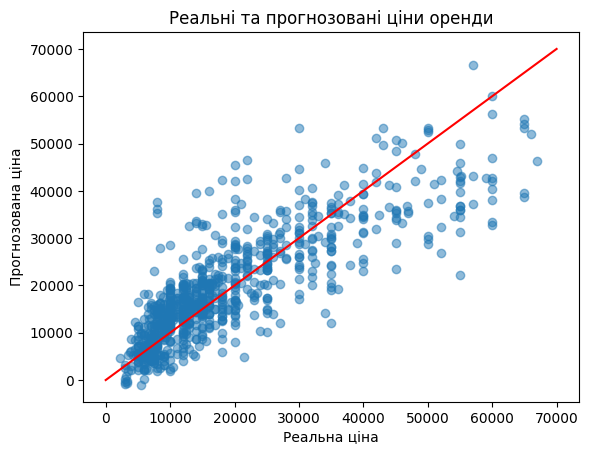

In [79]:
plt.scatter(y_test, y_test_pred, alpha=0.5)
plt.xlabel('Реальна ціна')
plt.ylabel('Прогнозована ціна')
plt.title('Реальні та прогнозовані ціни оренди')
plt.plot([0, 70000], [0, 70000], color='red')
plt.show()


На графіку видно, що модель загалом непогано прогнозує ціни на оренду, оскільки багато точок знаходяться недалеко від червоної лінії. Але є й помилки, особливо для квартир із високою вартістю оренди. Отже, модель працює, проте її прогнози ще можна покращити.

## Завдання 7: Аналіз помилок (4 бали)

**Що потрібно зробити:**
1. Обчисліть помилки (residuals = реальні - прогнозовані значення)
2. Побудуйте гістограму розподілу помилок
3. Створіть scatter plot помилок відносно величини прогнозованих значень. Чи росте помилка з ростом прогнозованого значення?
4. Знайдіть 5 прогнозів з найбільшими помилками
5. Проаналізуйте, на яких типах житла модель помиляється найбільше. Типи можна розрізняти за кількістю кімнат чи містом, наприклад.
6. Подумайте і напишіть, які наступні кроки ви б зробили, аби поліпшити якість моделі. Опціонально можна їх зробити і ми перевіримо :)

In [80]:
residuals = y_test - y_test_pred

In [81]:
residuals[:5]

,Rent
507,3566.167135
4664,-2481.425600
2166,-1886.434898
206,-1804.683493
2184,1183.975991


(array([  2.,   2.,   4.,   2.,   5.,   6.,   4.,   4.,  10.,  25.,  53.,
         85., 115., 144., 105.,  80.,  71.,  34.,  20.,  18.,  17.,   9.,
          7.,  10.,   5.,   2.,   3.,   2.,   0.,   1.]),
 array([-29548.20164576, -27473.64684823, -25399.09205069, -23324.53725315,
        -21249.98245561, -19175.42765807, -17100.87286054, -15026.318063  ,
        -12951.76326546, -10877.20846792,  -8802.65367038,  -6728.09887285,
         -4653.54407531,  -2578.98927777,   -504.43448023,   1570.1203173 ,
          3644.67511484,   5719.22991238,   7793.78470992,   9868.33950746,
         11942.89430499,  14017.44910253,  16092.00390007,  18166.55869761,
         20241.11349515,  22315.66829268,  24390.22309022,  26464.77788776,
         28539.3326853 ,  30613.88748284,  32688.44228037]),
 <BarContainer object of 30 artists>)

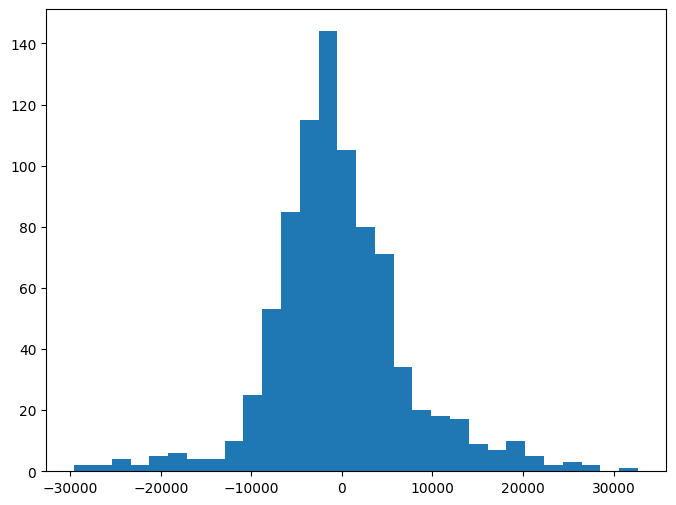

In [82]:
plt.figure(figsize=(8, 6))
plt.hist(residuals, bins=30)

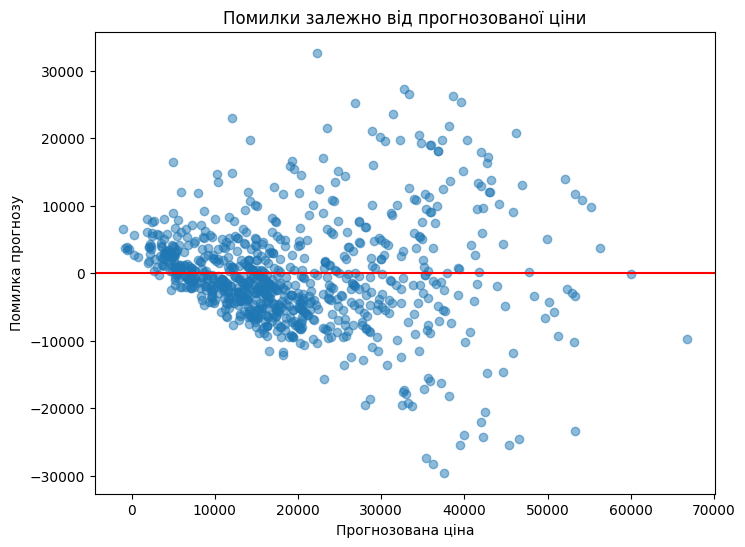

In [84]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_pred, residuals, alpha=0.5)
plt.axhline(0, color='red')
plt.xlabel('Прогнозована ціна')
plt.ylabel('Помилка прогнозу')
plt.title('Помилки залежно від прогнозованої ціни')
plt.show()

На графіку видно, що для квартир із нижчою прогнозованою ціною помилки зазвичай менші. Коли прогнозована ціна зростає, помилки стають більшими, а точки сильніше розкидані. Це означає, що модель менш точно прогнозує вартість дорожчих квартир.

In [85]:
absolute_errors = abs(residuals)
absolute_errors.head()

,Rent
507,3566.167135
4664,2481.425600
2166,1886.434898
206,1804.683493
2184,1183.975991


In [86]:
absolute_errors.nlargest(5)

,Rent
4408,32688.442280
549,29548.201646
852,28189.218425
904,27373.345254
2826,27306.916796


In [87]:
df.loc[absolute_errors.nlargest(5).index]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
4408,2022-06-18,2,55000,1325,6 out of 8,Super Area,Gachibowli,Hyderabad,Furnished,Bachelors/Family,2,Contact Owner
549,2022-06-02,2,8000,650,Upper Basement out of 9,Carpet Area,"Nakoda Heights, Nalasopara",Mumbai,Semi-Furnished,Family,2,Contact Agent
852,2022-05-06,2,8000,890,4 out of 4,Carpet Area,new panvel,Mumbai,Unfurnished,Bachelors/Family,2,Contact Owner
904,2022-06-20,2,8000,550,3 out of 9,Carpet Area,"Nakoda Heights, Nalasopara",Mumbai,Unfurnished,Family,2,Contact Agent
2826,2022-05-14,3,60000,1600,3 out of 4,Super Area,Greater Kailash,Delhi,Semi-Furnished,Bachelors/Family,3,Contact Owner


In [88]:
error_df = df.loc[y_test.index].copy()

In [89]:
error_df['Absolute_Error'] = absolute_errors
error_df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Absolute_Error
507,2022-04-28,1,3300,175,Ground out of 2,Super Area,New Town,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner,3566.167135
4664,2022-05-16,2,13000,1100,3 out of 5,Super Area,"Chandanagar, NH 9",Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner,2481.425600
2166,2022-06-08,1,9000,600,3 out of 4,Carpet Area,"Chelekare, Kalyan Nagar, Outer Ring Road",Bangalore,Semi-Furnished,Family,1,Contact Owner,1886.434898
206,2022-06-27,3,15000,1400,1 out of 3,Super Area,Survey Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner,1804.683493
2184,2022-04-29,2,25000,1350,12 out of 13,Super Area,Doddaballapur Road,Bangalore,Semi-Furnished,Bachelors/Family,2,Contact Owner,1183.975991


In [90]:
error_df.groupby('BHK')['Absolute_Error'].mean()

,Absolute_Error
BHK,
1,4285.242526
2,5146.062827
3,7473.084491
4,11940.283533
6,11035.238789


In [91]:
error_df.groupby('BHK')['Absolute_Error'].count()

,Absolute_Error
BHK,
1,224
2,448
3,155
4,16
6,2


За результатами аналізу видно, що зі збільшенням кількості кімнат середня помилка прогнозування загалом зростає. Найменша помилка спостерігається для однокімнатних квартир, а найбільша — для чотирикімнатних. Однак квартир із чотирма та шістьма кімнатами у вибірці мало, тому ці результати можуть бути менш надійними.

In [92]:
error_df.groupby('City')['Absolute_Error'].mean()

,Absolute_Error
City,
Bangalore,4025.505433
Chennai,5255.189835
Delhi,6111.446108
Hyderabad,5159.505929
Kolkata,3985.180451
Mumbai,9293.890288


За результатами аналізу видно, що найбільше модель помиляється при прогнозуванні цін на оренду в Мумбаї — у середньому приблизно на 9 294 рупії. Найменша середня помилка спостерігається в Калькутті — близько 3 985 рупій. Можливо, для точніших прогнозів потрібно краще враховувати особливості ринку оренди в різних містах.

Щоб покращити якість моделі, я б спробувала додати більше інформації про розташування квартир, особливо про конкретні райони міст. Також можна було б зібрати більше даних про великі та дорогі квартири, оскільки для них модель частіше помиляється. Після цього я б повторно навчила модель і порівняла результати, щоб перевірити, чи стала вона точнішою.